# Vecka 3 — FFT, fönsterfunktioner och PSD

**Syfte:** gå från tidsdomän till frekvensdomän. Förstå vad FFT:n faktiskt mäter, varför spektralt läckage uppstår, hur fönsterfunktioner påverkar spektret och hur effektspektraltäthet (PSD) skattas med periodogram och Welch.

Notebooken hör ihop med `docs/vecka_03_teori.md` och `R/vecka_03_fft_psd.R`. Parametrarna är desamma som i vecka 2:

| Parameter | Värde |
|---|---|
| Signal | 440 Hz sinus, amplitud 0,8 |
| Samplingsfrekvens | 16 000 Hz |
| FFT-längd (fönsterexperiment) | N = 1 024 → Δf = 15,625 Hz |
| Svag ton (fönsterexperiment) | 1 000 Hz, amplitud 0,008 (−40 dB) |
| Brus (PSD) | vitt gaussiskt brus, σ = 0,1, seed 42 |
| Welch | Hann, 1 024 sampel, 50 % överlapp |

Alla signaler är syntetiska. Kör cellerna uppifrån och ned (*Restart & Run All*).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import get_window, periodogram, welch
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "figures"
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

# Gemensamma parametrar (samma som vecka 2)
FS = 16000
F_SIGNAL = 440
AMPLITUD = 0.8
DURATION = 1.0

t = np.arange(int(FS * DURATION)) / FS
signal = AMPLITUD * np.sin(2 * np.pi * F_SIGNAL * t)

def amplitudspektrum(x, fs, fonster=None):
    # Ensidigt amplitudspektrum, skalat så att en sinus med amplitud A ger toppen A
    n = len(x)
    w = np.ones(n) if fonster is None else fonster
    X = np.fft.rfft(x * w)
    amp = np.abs(X) * 2 / np.sum(w)
    amp[0] /= 2                      # DC räknas bara en gång
    return np.fft.rfftfreq(n, d=1 / fs), amp

print(f"Antal sampel: {len(signal)} | fs: {FS} Hz | Δf för hela signalen: {FS / len(signal)} Hz")

Antal sampel: 16000 | fs: 16000 Hz | Δf för hela signalen: 1.0 Hz


## 1. FFT — från tid till frekvens

DFT:n av *N* sampel ger *N* frekvenskomponenter med avståndet **Δf = fs / N** (frekvensupplösning). För en reell signal räcker den första halvan (0 … fs/2), och amplituden skalas med `2/N` för att toppen ska motsvara sinusens amplitud.

Här jämförs tre FFT-längder: längre analysfönster ger finare frekvensupplösning.

In [2]:
rader = []
for n in [16000, 1024, 256]:
    f, amp = amplitudspektrum(signal[:n], FS)
    k = np.argmax(amp)
    rader.append({
        "N": n,
        "Längd (ms)": 1000 * n / FS,
        "Δf (Hz)": FS / n,
        "Uppmätt topp (Hz)": f[k],
        "Toppamplitud": round(float(amp[k]), 3),
        "440 Hz på en bin": (F_SIGNAL / (FS / n)).is_integer(),
    })
fft_tabell = pd.DataFrame(rader)
fft_tabell

N,Längd (ms),Δf (Hz),Uppmätt topp (Hz),Toppamplitud,440 Hz på en bin
16000,1000.0,1.000,440.0,0.800,True
1024,64.0,15.625,437.5,0.765,False
256,16.0,62.500,437.5,0.796,False


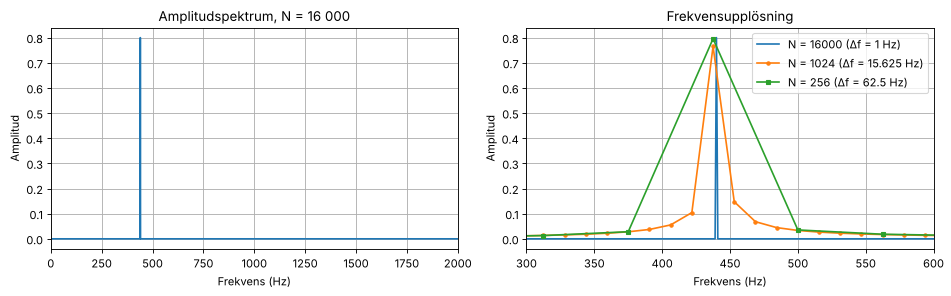

In [3]:
f, amp = amplitudspektrum(signal, FS)
assert f[np.argmax(amp)] == 440 and abs(amp.max() - AMPLITUD) < 1e-9

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(f, amp)
axes[0].set(title="Amplitudspektrum, N = 16 000", xlabel="Frekvens (Hz)", ylabel="Amplitud", xlim=(0, 2000))
for n, stil in [(16000, "-"), (1024, "o-"), (256, "s-")]:
    fn, an = amplitudspektrum(signal[:n], FS)
    axes[1].plot(fn, an, stil, markersize=3, label=f"N = {n} (Δf = {FS / n:g} Hz)")
axes[1].set(title="Frekvensupplösning", xlabel="Frekvens (Hz)", ylabel="Amplitud", xlim=(300, 600))
axes[1].legend()
for ax in axes:
    ax.grid(True)
plt.tight_layout()
plt.savefig(FIG_DIR / "vecka_03_fft.png", dpi=120)
plt.show()

## 2. Spektralt läckage

FFT:n förutsätter att analysfönstret innehåller ett helt antal perioder. Med N = 1 024 ligger binarna på multiplar av 15,625 Hz:

- **437,5 Hz** = bin 28 → exakt ett helt antal perioder → all energi i en bin.
- **440 Hz** = bin 28,16 → signalen "klipps" i kanterna → energin läcker ut till många binar och toppen blir lägre (*scalloping loss*).

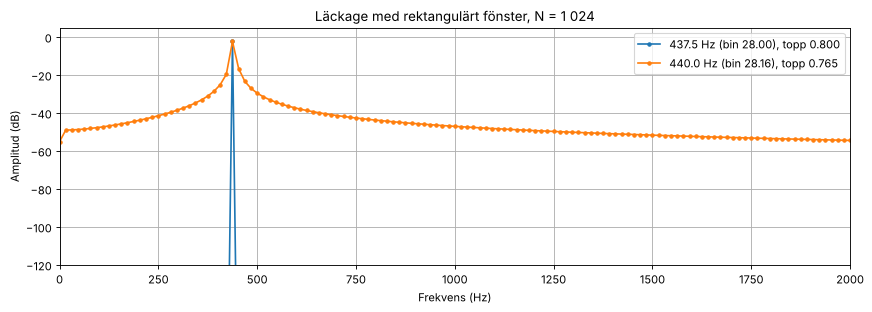

In [4]:
N = 1024
tn = np.arange(N) / FS
fig, ax = plt.subplots(figsize=(11, 4))
for frek in [437.5, 440.0]:
    fn, an = amplitudspektrum(AMPLITUD * np.sin(2 * np.pi * frek * tn), FS)
    db = 20 * np.log10(np.maximum(an, 1e-12))
    ax.plot(fn, db, "o-", markersize=3, label=f"{frek} Hz (bin {frek / (FS / N):.2f}), topp {an.max():.3f}")
ax.set(title="Läckage med rektangulärt fönster, N = 1 024", xlabel="Frekvens (Hz)",
       ylabel="Amplitud (dB)", xlim=(0, 2000), ylim=(-120, 5))
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.savefig(FIG_DIR / "vecka_03_lackage.png", dpi=120)
plt.show()

## 3. Fönsterfunktioner

Ett fönster tonar ned signalen mot kanterna och minskar därmed läckaget. Priset är en bredare huvudlob (sämre förmåga att skilja två närliggande frekvenser).

Fönstren definieras som periodiska (samma som `scipy.signal.get_window`), med `n = 0 … N−1`:

| Fönster | Formel |
|---|---|
| Rektangulärt | 1 |
| Hann | 0,5 − 0,5·cos(2πn/N) |
| Hamming | 0,54 − 0,46·cos(2πn/N) |
| Blackman | 0,42 − 0,5·cos(2πn/N) + 0,08·cos(4πn/N) |

Mått: **koherent förstärkning** (medelvärdet av fönstret), **ENBW** (ekvivalent brusbandbredd i binar), **högsta sidlob** och **huvudlobens bredd**.

In [5]:
def fonsterfunktion(namn, n):
    k = np.arange(n)
    return {
        "Rektangulärt": np.ones(n),
        "Hann": 0.5 - 0.5 * np.cos(2 * np.pi * k / n),
        "Hamming": 0.54 - 0.46 * np.cos(2 * np.pi * k / n),
        "Blackman": 0.42 - 0.5 * np.cos(2 * np.pi * k / n) + 0.08 * np.cos(4 * np.pi * k / n),
    }[namn]

FONSTER = ["Rektangulärt", "Hann", "Hamming", "Blackman"]
for namn, scipy_namn in [("Hann", "hann"), ("Hamming", "hamming"), ("Blackman", "blackman")]:
    assert np.allclose(fonsterfunktion(namn, N), get_window(scipy_namn, N))

def fonstermatt(w, pad=64):
    n = len(w)
    W = np.abs(np.fft.fft(w, n * pad))[: n * pad // 2]
    W_db = 20 * np.log10(W / W.max() + 1e-300)
    i = 1
    while W_db[i + 1] < W_db[i]:      # första nollstället = slutet av huvudloben
        i += 1
    return {
        "Koherent förstärkning": round(w.mean(), 3),
        "ENBW (bin)": round(n * np.sum(w**2) / np.sum(w) ** 2, 3),
        "Högsta sidlob (dB)": round(W_db[i:].max(), 1),
        "3 dB-bredd (bin)": round(2 * np.argmax(W_db < -3.0103) / pad, 2),
        "Huvudlob nollställe–nollställe (bin)": round(2 * i / pad, 1),
    }

fonster_tabell = pd.DataFrame([{"Fönster": namn, **fonstermatt(fonsterfunktion(namn, N))} for namn in FONSTER])
fonster_tabell

Fönster,Koherent förstärkning,ENBW (bin),Högsta sidlob (dB),3 dB-bredd (bin),Huvudlob nollställe–nollställe (bin)
Rektangulärt,1.00,1.000,-13.3,0.91,2.0
Hann,0.50,1.500,-31.5,1.47,4.0
Hamming,0.54,1.363,-42.7,1.31,4.0
Blackman,0.42,1.727,-58.1,1.66,6.0


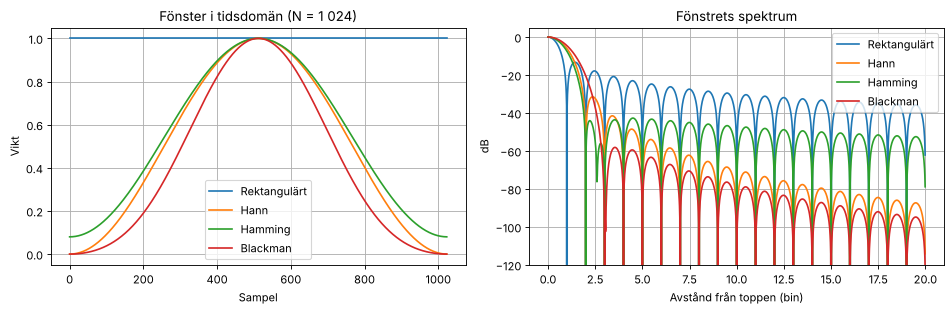

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pad = 64
for namn in FONSTER:
    w = fonsterfunktion(namn, N)
    axes[0].plot(w, label=namn)
    W = np.abs(np.fft.fft(w, N * pad))
    W_db = 20 * np.log10(W / W.max() + 1e-300)
    bins = np.arange(N * pad) / pad
    axes[1].plot(bins[: 20 * pad], W_db[: 20 * pad], label=namn)
axes[0].set(title="Fönster i tidsdomän (N = 1 024)", xlabel="Sampel", ylabel="Vikt")
axes[1].set(title="Fönstrets spektrum", xlabel="Avstånd från toppen (bin)", ylabel="dB", ylim=(-120, 5))
for ax in axes:
    ax.grid(True)
axes[0].legend(loc="lower center")
axes[1].legend(loc="upper right")
plt.tight_layout()
plt.savefig(FIG_DIR / "vecka_03_fonster.png", dpi=120)
plt.show()

### Experiment: hitta en svag ton bredvid en stark

Signal: 440 Hz med amplitud 0,8 plus en svag ton på 1 000 Hz med amplitud 0,008 (−40 dB). 1 000 Hz ligger exakt på bin 64, men läckaget från 440 Hz kan ändå dölja den.

**Framträdande** = nivån vid 1 000 Hz minus medelnivån fyra binar bort på båda sidor. Ett positivt värde betyder att tonen syns som en topp.

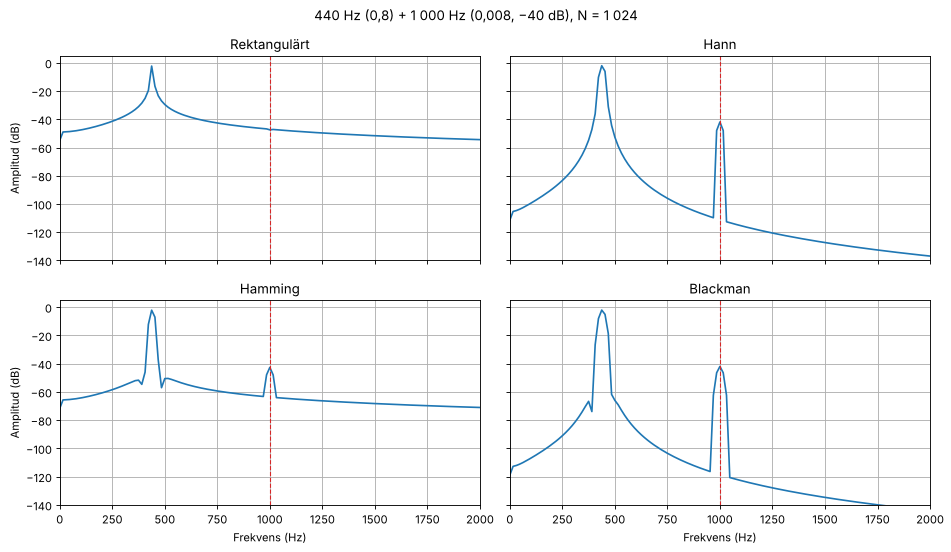

Fönster,Topp 440 Hz (amplitud),Nivå vid 1 000 Hz (dB),Framträdande (dB),Svag ton syns
Rektangulärt,0.765,-47.5,-0.5,False
Hann,0.787,-41.9,69.1,True
Hamming,0.784,-42.6,21.0,True
Blackman,0.790,-41.9,76.5,True


In [7]:
F_SVAG, A_SVAG = 1000, 0.008
x_tva = AMPLITUD * np.sin(2 * np.pi * F_SIGNAL * tn) + A_SVAG * np.sin(2 * np.pi * F_SVAG * tn)

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)
rader = []
for ax, namn in zip(axes.flat, FONSTER):
    fn, an = amplitudspektrum(x_tva, FS, fonsterfunktion(namn, N))
    db = 20 * np.log10(np.maximum(an, 1e-12))
    k = int(round(F_SVAG / (FS / N)))
    framtradande = db[k] - 0.5 * (db[k - 4] + db[k + 4])
    rader.append({
        "Fönster": namn,
        "Topp 440 Hz (amplitud)": round(float(an[int(round(F_SIGNAL / (FS / N)))]), 3),
        "Nivå vid 1 000 Hz (dB)": round(db[k], 1),
        "Framträdande (dB)": round(framtradande, 1),
        "Svag ton syns": framtradande > 6,
    })
    ax.plot(fn, db)
    ax.axvline(F_SVAG, color="tab:red", ls="--", lw=1)
    ax.set(title=namn, xlim=(0, 2000), ylim=(-140, 5))
    ax.grid(True)
for ax in axes[1]:
    ax.set_xlabel("Frekvens (Hz)")
for ax in axes[:, 0]:
    ax.set_ylabel("Amplitud (dB)")
fig.suptitle("440 Hz (0,8) + 1 000 Hz (0,008, −40 dB), N = 1 024")
plt.tight_layout()
plt.savefig(FIG_DIR / "vecka_03_svag_ton.png", dpi=120)
plt.show()

svag_ton_tabell = pd.DataFrame(rader)
assert not svag_ton_tabell.loc[0, "Svag ton syns"]          # rektangulärt döljer tonen
assert svag_ton_tabell.loc[1:, "Svag ton syns"].all()        # övriga fönster visar den
svag_ton_tabell

## 4. Effektspektraltäthet (PSD)

PSD beskriver hur signalens **effekt** fördelas över frekvens (enhet V²/Hz, här amplitud²/Hz). Två skattningar jämförs på en brusig signal (440 Hz-sinus + vitt brus med σ = 0,1):

- **Periodogram** — en FFT över hela signalen. Fin frekvensupplösning men stor varians i skattningen.
- **Welch** — signalen delas i överlappande segment (Hann, 1 024 sampel, 50 % överlapp) och periodogrammen medelvärdesbildas. Grövre upplösning men mycket lägre varians. Toppen hamnar på 437,5 Hz, närmaste bin till 440 Hz när Δf = 15,625 Hz.

Kontroller:
- **Parseval:** arean under PSD:n ska vara lika med signalens medeleffekt, `0,8²/2 + 0,1² = 0,33`.
- **Brusgolv:** vitt brus ger den ensidiga tätheten `σ² / (fs/2) = 0,01 / 8 000 = 1,25·10⁻⁶` (−59,0 dB).
- **SNR:** `10·log10(0,32 / 0,01) ≈ 15,05 dB`.

In [8]:
rng = np.random.default_rng(42)
x_brus = signal + 0.1 * rng.standard_normal(len(signal))

f_p, P_p = periodogram(x_brus, FS, window="boxcar")
f_w, P_w = welch(x_brus, FS, window="hann", nperseg=1024, noverlap=512)

def snr_fran_psd(f, P, f0=F_SIGNAL, bredd=50):
    df = f[1] - f[0]
    signalband = np.abs(f - f0) <= bredd
    brusband = ~signalband & (f > 0)
    brustathet = np.mean(P[brusband])   # medelvärde: periodogrammets värden är exponentialfördelade
    p_signal = P[signalband].sum() * df - brustathet * signalband.sum() * df
    p_brus = brustathet * (FS / 2)
    return 10 * np.log10(p_signal / p_brus)

brusband_p = (f_p > 1000) & (f_p < 7000)
brusband_w = (f_w > 1000) & (f_w < 7000)
psd_tabell = pd.DataFrame([
    {"Metod": namn,
     "Δf (Hz)": f[1] - f[0],
     "Parseval: area": round(P.sum() * (f[1] - f[0]), 4),
     "Brusgolv medel": f"{P[b].mean():.3e}",
     "Brusgolv std": f"{P[b].std():.3e}",
     "Topp (Hz)": f[np.argmax(P)],
     "SNR (dB)": round(snr_fran_psd(f, P), 2)}
    for namn, f, P, b in [("Periodogram", f_p, P_p, brusband_p), ("Welch", f_w, P_w, brusband_w)]
])
print("Medeleffekt i tidsdomän:", round(float(np.mean(x_brus**2)), 4), "| teoretiskt brusgolv: 1.250e-06")
psd_tabell

Medeleffekt i tidsdomän: 0.3321 | teoretiskt brusgolv: 1.250e-06


Metod,Δf (Hz),Parseval: area,Brusgolv medel,Brusgolv std,Topp (Hz),SNR (dB)
Periodogram,1.000,0.3321,1.255e-06,1.269e-06,440.0,15.05
Welch,15.625,0.3321,1.259e-06,2.263e-07,437.5,15.04


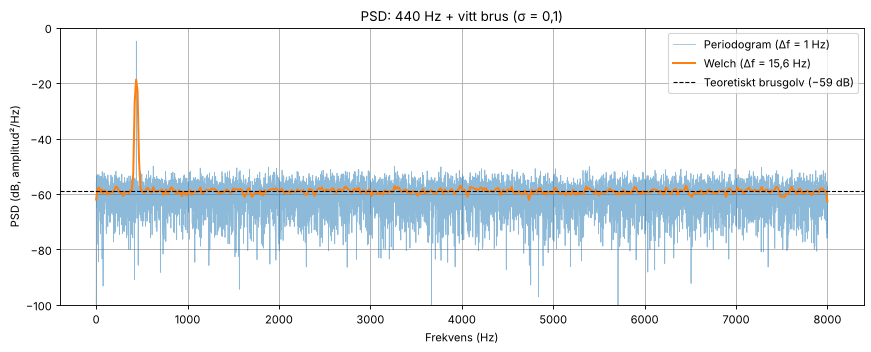

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(f_p, 10 * np.log10(P_p), alpha=0.5, lw=0.7, label="Periodogram (Δf = 1 Hz)")
ax.plot(f_w, 10 * np.log10(P_w), lw=1.8, label="Welch (Δf = 15,6 Hz)")
ax.axhline(10 * np.log10(0.01 / (FS / 2)), color="black", ls="--", lw=1, label="Teoretiskt brusgolv (−59 dB)")
ax.set(title="PSD: 440 Hz + vitt brus (σ = 0,1)", xlabel="Frekvens (Hz)", ylabel="PSD (dB, amplitud²/Hz)", ylim=(-100, 0))
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.savefig(FIG_DIR / "vecka_03_psd.png", dpi=120)
plt.show()

## 5. Tillämpning på WAV-filen från vecka 2

Samma metoder används på `data/test_signal_440hz.wav`. Om filen saknas (den är genererad och committas inte) skapas den på samma sätt som i vecka 2.

In [10]:
wav_path = DATA_DIR / "test_signal_440hz.wav"
if not wav_path.exists():
    wavfile.write(wav_path, FS, np.round(np.clip(signal, -1, 1) * 32767).astype(np.int16))
    print("WAV-filen saknades och skapades:", wav_path.relative_to(ROOT).as_posix())

las_fs, pcm = wavfile.read(wav_path)
x_wav = pcm.astype(np.float64) / 32768
f_wav, amp_wav = amplitudspektrum(x_wav, las_fs, fonsterfunktion("Hann", len(x_wav)))
f_wp, P_wp = welch(x_wav, las_fs, window="hann", nperseg=1024, noverlap=512)

wav_tabell = pd.DataFrame([
    ("Fil", wav_path.relative_to(ROOT).as_posix()),
    ("Toppfrekvens, FFT med Hann (Hz)", f_wav[np.argmax(amp_wav)]),
    ("Toppamplitud", round(float(amp_wav.max()), 4)),
    ("Toppfrekvens, Welch (Hz)", f_wp[np.argmax(P_wp)]),
    ("Parseval: PSD-area", round(float(P_wp.sum() * (f_wp[1] - f_wp[0])), 4)),
    ("Medeleffekt i tidsdomän", round(float(np.mean(x_wav**2)), 4)),
], columns=["Kontroll", "Värde"])
assert f_wav[np.argmax(amp_wav)] == 440
wav_tabell

WAV-filen saknades och skapades: data/test_signal_440hz.wav


Kontroll,Värde
Fil,data/test_signal_440hz.wav
"Toppfrekvens, FFT med Hann (Hz)",440.0
Toppamplitud,0.8
"Toppfrekvens, Welch (Hz)",437.5
Parseval: PSD-area,0.32
Medeleffekt i tidsdomän,0.32


## 6. Slutsatser

- **FFT:** toppen hamnar på 440 Hz med amplitud 0,8 när skalningen är `2/N`. Frekvensupplösningen bestäms bara av analysfönstrets längd, `Δf = fs/N`: 1 Hz vid N = 16 000, 15,6 Hz vid 1 024 och 62,5 Hz vid 256.
- **Läckage:** 437,5 Hz (exakt på en bin) ger en ren topp, medan 440 Hz (bin 28,16) läcker energi över hela spektret och toppen sjunker från 0,8 till cirka 0,77.
- **Fönster:** sidlobsnivåerna blev −13 (rektangulärt), −31 (Hann), −43 (Hamming) och −58 dB (Blackman), i takt med att huvudloben breddas. En ton på −40 dB döljs helt av det rektangulära fönstrets läckage men syns tydligt med Hann och Blackman. Hann är ett bra standardval för ljud.
- **PSD:** både periodogram och Welch uppfyller Parseval (area ≈ 0,332) och ger rätt brusgolv (≈ 1,25·10⁻⁶) och SNR (≈ 15 dB). Welch har ungefär 5–6 gånger lägre spridning i brusgolvet, på bekostnad av grövre frekvensupplösning.
- **Till pipelinen:** Hann-fönster och Welch-PSD är rimliga standardval för de kommande veckorna (filter i vecka 4, STFT i vecka 5).

### Självkontroll
1. Vad bestämmer frekvensupplösningen, och varför hjälper inte zero-padding att skilja två närliggande toner?
2. Varför uppstår läckage när signalen inte har ett helt antal perioder i fönstret?
3. Vilken avvägning gör man mellan huvudlobens bredd och sidlobernas nivå?
4. Varför har Welch-skattningen lägre varians än periodogrammet, och vad förlorar man?